In [17]:

import numpy as np

# Input medical image features
X = np.array([2.0, 3.0])

# Weights and bias
W = np.array([0.5, 0.8])
b = 0.6

# 1. Element-wise multiplication
element_result = X * W
print("Element-wise Multiplication:", element_result)

# 2. Matrix multiplication (weighted sum)
Z = np.dot(X, W)
print("Matrix Multiplication:", Z)

# 3. Vector addition (adding bias)
Z = Z + b
print("After Adding Bias:", Z)

# 4. Sigmoid activation function
output = 1 / (1 + np.exp(-Z))
print("Forward Propagation Output:", output)

# 5. Classification
if output >= 0.5:
    print("Diagnosis: Abnormal")
else:
    print("Diagnosis: Normal")

Element-wise Multiplication: [1.  2.4]
Matrix Multiplication: 3.4000000000000004
After Adding Bias: 4.0
Forward Propagation Output: 0.9820137900379085
Diagnosis: Abnormal


# **LAB EXPERIMENTS**

1.Construct and verify the performance of bi-level and multi-level confusion
matrix using Python.

Multi-class Confusion Matrix:
[[2 1 0]
 [0 2 1]
 [1 0 3]]

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.67      0.67      0.67         3
     Class 1       0.67      0.67      0.67         3
     Class 2       0.75      0.75      0.75         4

    accuracy                           0.70        10
   macro avg       0.69      0.69      0.69        10
weighted avg       0.70      0.70      0.70        10



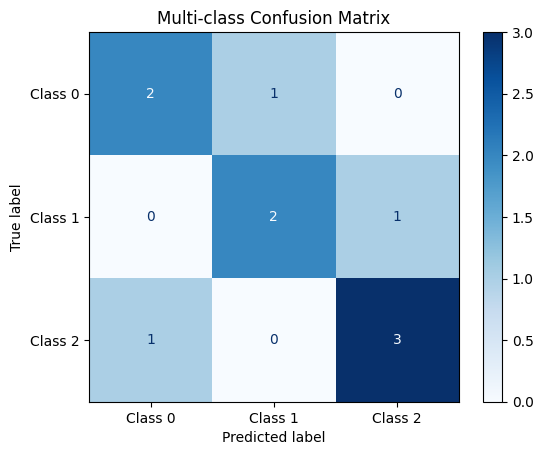


Class 0 vs Rest:
[[6 1]
 [1 2]]

Class 1 vs Rest:
[[6 1]
 [1 2]]

Class 2 vs Rest:
[[5 1]
 [1 3]]


In [18]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Actual and predicted values for three classes
y_true = [0, 0, 0, 1, 1, 1, 2, 2, 2, 2]
y_pred = [0, 0, 1, 1, 1, 2, 2, 0, 2, 2]

# Multi-class confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

print("Multi-class Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Class 0", "Class 1", "Class 2"],
    zero_division=0
))

# Display multi-class matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Multi-class Confusion Matrix")
plt.show()

# Binary confusion matrix for each class vs rest
for class_id in [0, 1, 2]:
    actual_binary = [
        1 if value == class_id else 0 for value in y_true
    ]
    predicted_binary = [
        1 if value == class_id else 0 for value in y_pred
    ]

    binary_cm = confusion_matrix(
        actual_binary, predicted_binary, labels=[0, 1]
    )

    print(f"\nClass {class_id} vs Rest:")
    print(binary_cm)


2.Verification of the overfitting issue by using a chosen numerical database using
Python.

Training Accuracy: 0.991
Testing Accuracy : 0.896
Accuracy Gap     : 0.095


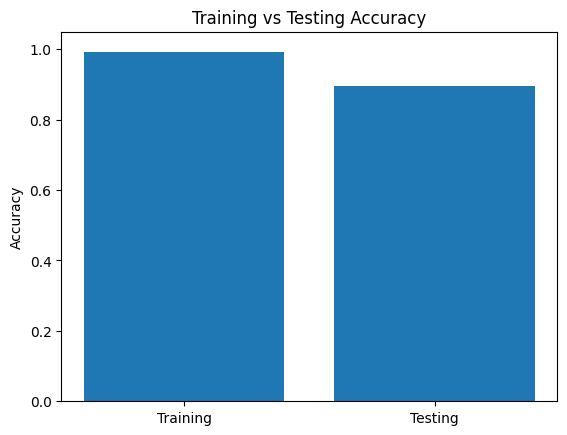

No large accuracy gap in this run.


In [19]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# Generate a numerical two-class dataset
X, y = make_moons(
    n_samples=160,
    noise=0.25,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Create a neural network model
model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(100, 100),
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=42
    )
)

# Train the model
model.fit(X_train, y_train)

# Predict training and testing data
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

# Calculate accuracy
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print("Training Accuracy:", round(train_acc, 3))
print("Testing Accuracy :", round(test_acc, 3))
print("Accuracy Gap     :", round(train_acc - test_acc, 3))

# Compare the accuracies
plt.bar(
    ["Training", "Testing"],
    [train_acc, test_acc]
)
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.show()

if train_acc - test_acc > 0.10:
    print("Possible overfitting detected.")
else:
    print("No large accuracy gap in this run.")


3.Analysing the performance of linear regression process using a chosen
numerical database using Python

Mean Absolute Error: 0.533
Mean Squared Error : 0.556
Root Mean Squared Error: 0.746
R-squared Score: 0.576


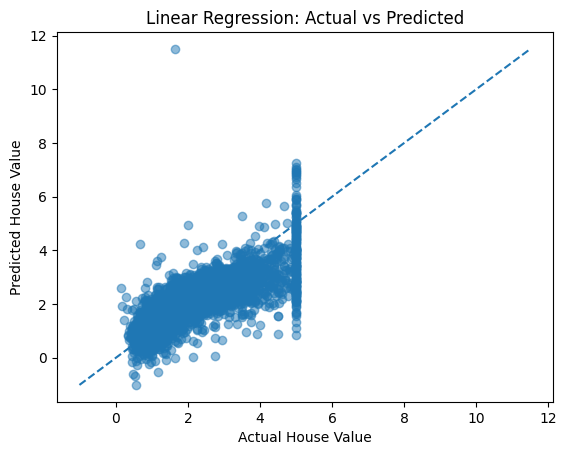

In [20]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load numerical housing dataset
data = fetch_california_housing()
X = data.data
y = data.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 3))
print("Mean Squared Error :", round(mse, 3))
print("Root Mean Squared Error:", round(rmse, 3))
print("R-squared Score:", round(r2, 3))

# Plot actual vs predicted values
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Linear Regression: Actual vs Predicted")

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "--")

plt.show()


4.Analysing the performance of logistic regression process using a chosen
numerical database using Python

Accuracy: 0.982
ROC-AUC : 0.995

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



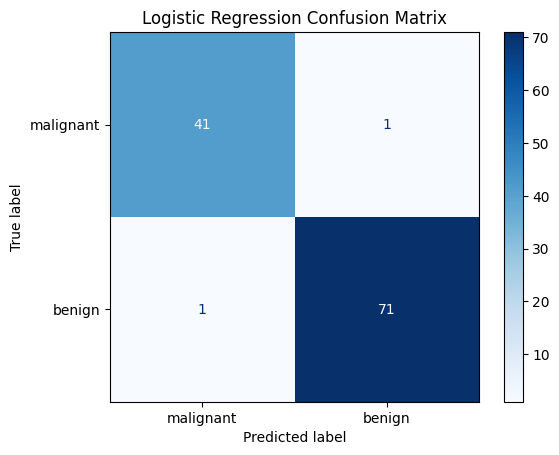

In [21]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Load the breast cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale features and build the classifier
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=5000,
        random_state=42
    )
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", round(accuracy, 3))
print("ROC-AUC :", round(roc_auc, 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.show()


5 Demonstrating the performance of gradient descent algorithm using Python


Learned Weight: 1.943
Learned Bias: 1.06
Final MSE: 0.825


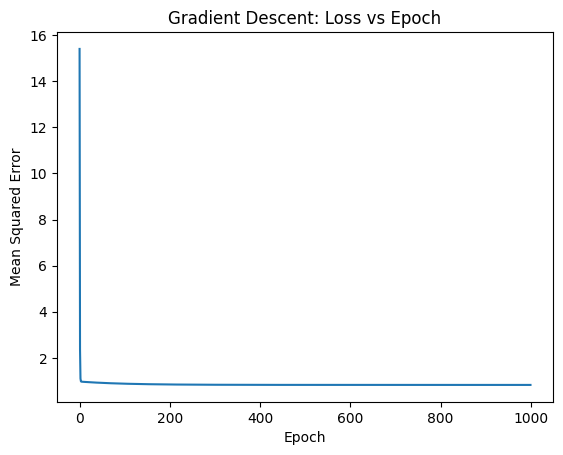

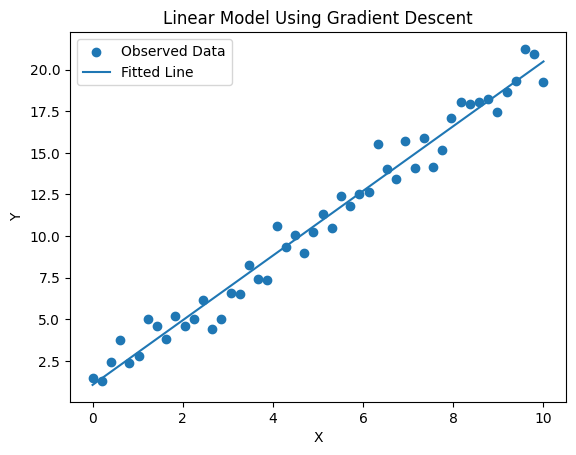

In [22]:

import numpy as np
import matplotlib.pyplot as plt

# Generate sample numerical data
np.random.seed(42)
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + np.random.normal(0, 1, size=X.shape)

# Initialize weight and bias
w = 0.0
b = 0.0

learning_rate = 0.01
epochs = 1000
n = len(X)

loss_history = []

# Gradient descent training
for epoch in range(epochs):
    y_pred = w * X + b
    error = y_pred - y

    # Calculate gradients
    dw = (2 / n) * np.sum(error * X)
    db = (2 / n) * np.sum(error)

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # Calculate mean squared error
    loss = np.mean((w * X + b - y) ** 2)
    loss_history.append(loss)

# Display final parameters
print("Learned Weight:", round(w, 3))
print("Learned Bias:", round(b, 3))
print("Final MSE:", round(loss_history[-1], 3))

# Plot loss over epochs
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Loss vs Epoch")
plt.show()

# Plot fitted regression line
plt.scatter(X, y, label="Observed Data")
plt.plot(X, w * X + b, label="Fitted Line")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Model Using Gradient Descent")
plt.legend()
plt.show()


6 Verifying the performance of a image pre-processing with Otsu’s function using
Python


Otsu Threshold Value: 49.0


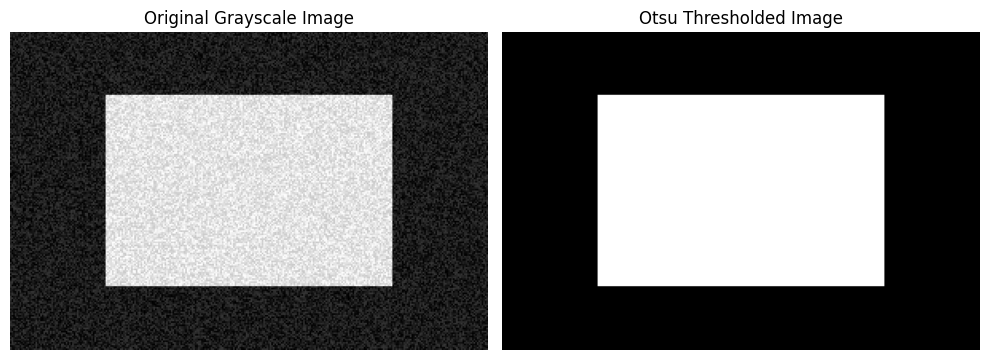

In [23]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a sample grayscale image
image = np.zeros((200, 300), dtype=np.uint8)
image[40:160, 60:240] = 180

# Add some noise
noise = np.random.randint(0, 50, image.shape, dtype=np.uint8)
image = cv2.add(image, noise)

# Apply Otsu thresholding
threshold, binary_image = cv2.threshold(
    image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", threshold)

# Display original and thresholded images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray")
plt.title("Otsu Thresholded Image")
plt.axis("off")

plt.tight_layout()
plt.show()


7 Verifying the performance of a image pre-processing with watershed algorithm
using Python


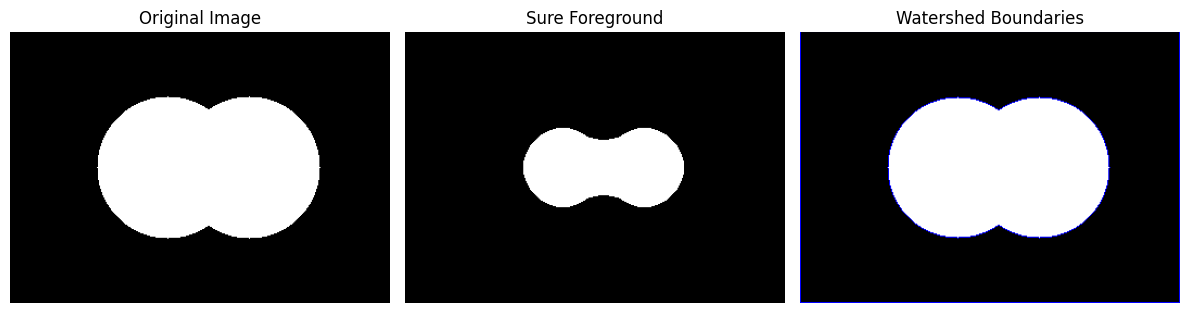

Watershed segmentation completed.


In [24]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a black image with two touching white circles
image = np.zeros((250, 350, 3), dtype=np.uint8)

cv2.circle(image, (145, 125), 65, (255, 255, 255), -1)
cv2.circle(image, (220, 125), 65, (255, 255, 255), -1)

# Convert to grayscale and create a binary image
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY
)

# Remove small noise using morphological opening
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel, iterations=2
)

# Find sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Find sure foreground using distance transform
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(
    dist, 0.45 * dist.max(), 255, 0
)
sure_fg = np.uint8(sure_fg)

# Find unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers for watershed
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(image.copy(), markers)

# Mark boundaries in red
result = image.copy()
result[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sure_fg, cmap="gray")
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Boundaries")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Watershed segmentation completed.")


10 Performance evaluation of Linear regression Classifier using Breast cancer or
Iris database


Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



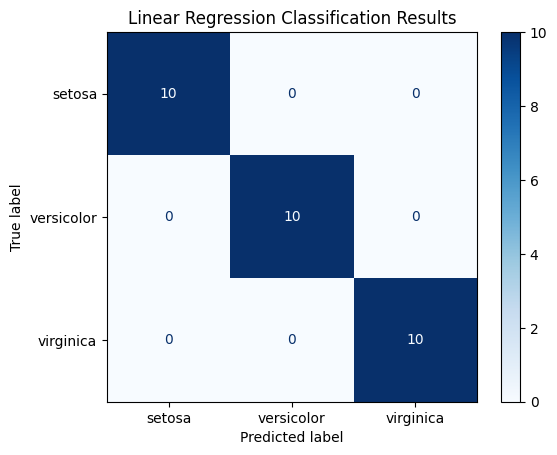

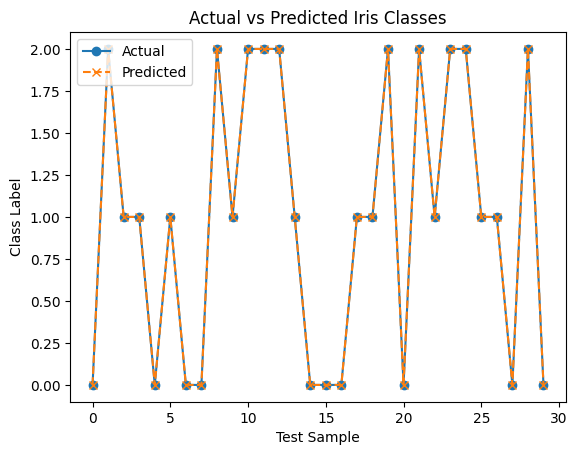

In [25]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict continuous class scores
y_scores = model.predict(X_test)

# Convert scores into class labels
y_pred = np.clip(
    np.rint(y_scores), 0, 2
).astype(int)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=iris.target_names,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
display.plot(cmap="Blues", values_format="d")
plt.title("Linear Regression Classification Results")
plt.show()

# Compare actual and predicted labels
plt.plot(y_test, "o-", label="Actual")
plt.plot(y_pred, "x--", label="Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Class Label")
plt.title("Actual vs Predicted Iris Classes")
plt.legend()
plt.show()


11 Performance evaluation of Logistic regression Classifier using Breast cancer or
Iris database


In [26]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



12 Performance evaluation of Random Forest Classifier using Breast cancer or Iris
database

In [27]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



13 Performance evaluation of Decision Tree Classifier using Breast cancer or Iris
database

In [28]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



14 Performance evaluation of K-Nearest Neighbor Classifier using Breast cancer or
Iris database


In [29]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



15 Performance evaluation of Support Vector Machine Classifier using Breast
cancer or Iris database

In [30]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



16 Implementing the Hyper parameter Tuning on a chosen neural network scheme
and verifying the change in the attained output.

In [31]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

settings = [
    {"hidden_layer_sizes": (32,), "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (64,), "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (32, 16), "learning_rate_init": 0.01}
]

for i, params in enumerate(settings, start=1):
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            **params,
            max_iter=1500,
            random_state=42
        )
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"Model {i}: {params}")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print()

Model 1: {'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}
Accuracy: 0.9561

Model 2: {'hidden_layer_sizes': (64,), 'learning_rate_init': 0.001}
Accuracy: 0.9561

Model 3: {'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.01}
Accuracy: 0.9561



17

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Select digits 0 and 1
train_mask = y_train < 2
test_mask = y_test < 2

X_train = X_train[train_mask]
y_train = y_train[train_mask]
X_test = X_test[test_mask]
y_test = y_test[test_mask]

# Normalize images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train[..., None]
X_test = X_test[..., None]

# Build CNN
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.1
)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", accuracy)

predictions = model.predict(X_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, predictions))

Epoch 1/3
357/357 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9939 - loss: 0.0272 - val_accuracy: 0.9984 - val_loss: 0.0053
Epoch 2/3
357/357 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9989 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 4.3380e-04
Epoch 3/3
357/357 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9996 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 1.7584e-04
Test Accuracy: 0.9990543723106384
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       980
           1       1.00      1.00      1.00      1135

    accuracy                           1.00      2115
   macro avg       1.00      1.00      1.00      2115
weighted avg       1.00      1.00      1.00      2115



18 Implementing Convolutional Neural Network (CNN) models to execute the
binary classification with varied values of; batch size, optimizer, activation
function and learning rate using Python

In [33]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load MNIST digits 0 and 1
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

train_mask = y_train < 2
test_mask = y_test < 2

X_train = X_train[train_mask].astype("float32") / 255.0
y_train = y_train[train_mask]
X_test = X_test[test_mask].astype("float32") / 255.0
y_test = y_test[test_mask]

X_train = X_train[..., None]
X_test = X_test[..., None]

# Different configurations
experiments = [
    (16, "adam", "relu", 0.001),
    (32, "sgd", "relu", 0.01),
    (64, "adam", "tanh", 0.001)
]

for i, (batch_size, optimizer_name, activation, lr) in enumerate(
    experiments, start=1
):
    tf.keras.backend.clear_session()

    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, activation=activation),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(32, activation=activation),
        layers.Dense(2, activation="softmax")
    ])

    if optimizer_name == "adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    else:
        optimizer = tf.keras.optimizers.SGD(learning_rate=lr)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train, y_train,
        epochs=2,
        batch_size=batch_size,
        validation_split=0.1,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print(f"Experiment {i}")
    print("Batch Size:", batch_size)
    print("Optimizer:", optimizer_name)
    print("Activation:", activation)
    print("Learning Rate:", lr)
    print("Test Accuracy:", round(accuracy, 4))
    print()

Experiment 1
Batch Size: 16
Optimizer: adam
Activation: relu
Learning Rate: 0.001
Test Accuracy: 0.9991

Experiment 2
Batch Size: 32
Optimizer: sgd
Activation: relu
Learning Rate: 0.01
Test Accuracy: 0.9986

Experiment 3
Batch Size: 64
Optimizer: adam
Activation: tanh
Learning Rate: 0.001
Test Accuracy: 0.9962



19 Implementing Convolutional Neural Network (CNN) models to achieve the
segmentation (UNet) using Python

Epoch 1/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 403ms/step - accuracy: 0.9128 - loss: 0.5992 - val_accuracy: 0.9257 - val_loss: 0.4056
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 365ms/step - accuracy: 0.9495 - loss: 0.1772 - val_accuracy: 0.9903 - val_loss: 0.0625
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 479ms/step - accuracy: 0.9923 - loss: 0.0438 - val_accuracy: 0.9946 - val_loss: 0.0427
Epoch 4/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 397ms/step - accuracy: 0.9952 - loss: 0.0282 - val_accuracy: 0.9929 - val_loss: 0.0224
Epoch 5/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 368ms/step - accuracy: 0.9957 - loss: 0.0125 - val_accuracy: 0.9956 - val_loss: 0.0105
Test Loss: 0.008713257499039173
Test Accuracy: 0.996539294719696


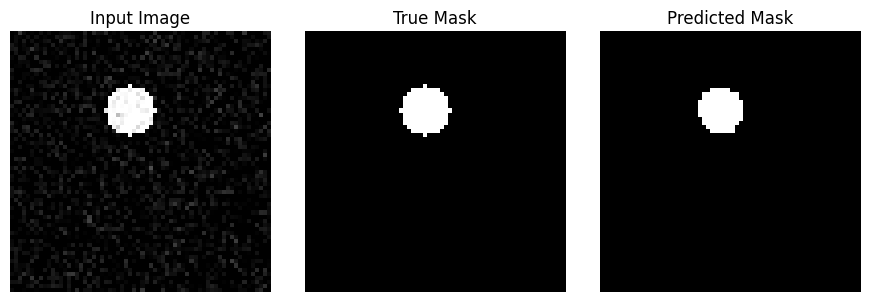

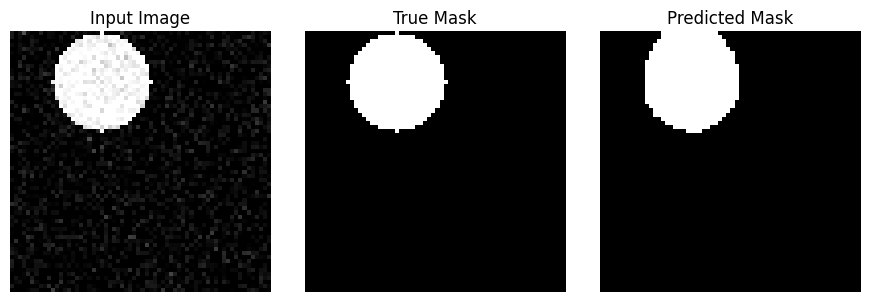

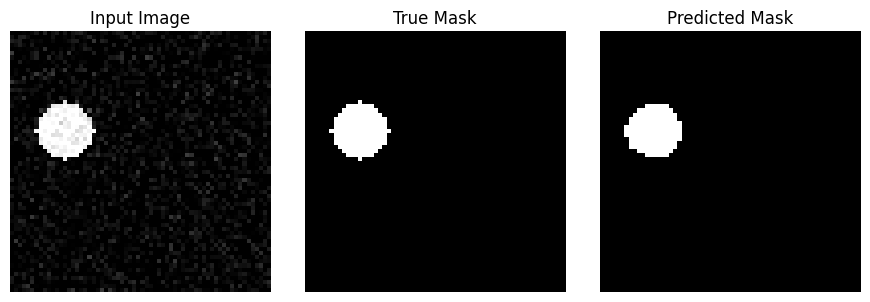

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# Generate synthetic images and segmentation masks
np.random.seed(42)

def generate_data(n=200, size=64):
    images = np.zeros((n, size, size, 1), dtype=np.float32)
    masks = np.zeros((n, size, size, 1), dtype=np.float32)

    for i in range(n):
        x = np.random.randint(12, 42)
        y = np.random.randint(12, 42)
        r = np.random.randint(6, 13)

        yy, xx = np.ogrid[:size, :size]
        circle = (xx - x) ** 2 + (yy - y) ** 2 <= r ** 2

        masks[i, :, :, 0] = circle.astype(np.float32)
        images[i, :, :, 0] = masks[i, :, :, 0]
        images[i, :, :, 0] += np.random.normal(
            0, 0.08, (size, size)
        )

    images = np.clip(images, 0, 1)
    return images, masks

X, Y = generate_data()

X_train, X_test = X[:160], X[160:]
Y_train, Y_test = Y[:160], Y[160:]

# Build a small U-Net model
inputs = layers.Input((64, 64, 1))

c1 = layers.Conv2D(16, 3, activation="relu", padding="same")(inputs)
c1 = layers.Conv2D(16, 3, activation="relu", padding="same")(c1)
p1 = layers.MaxPooling2D()(c1)

c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(p1)
c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(c2)
p2 = layers.MaxPooling2D()(c2)

b = layers.Conv2D(64, 3, activation="relu", padding="same")(p2)

u2 = layers.UpSampling2D()(b)
u2 = layers.Concatenate()([u2, c2])
c3 = layers.Conv2D(32, 3, activation="relu", padding="same")(u2)

u1 = layers.UpSampling2D()(c3)
u1 = layers.Concatenate()([u1, c1])
c4 = layers.Conv2D(16, 3, activation="relu", padding="same")(u1)

outputs = layers.Conv2D(1, 1, activation="sigmoid")(c4)

model = models.Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    X_train, Y_train,
    epochs=5,
    batch_size=16,
    validation_split=0.1
)

loss, accuracy = model.evaluate(X_test, Y_test, verbose=0)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Display segmentation output
predictions = model.predict(X_test[:3], verbose=0)

for i in range(3):
    plt.figure(figsize=(9, 3))

    plt.subplot(1, 3, 1)
    plt.imshow(X_test[i, :, :, 0], cmap="gray")
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(Y_test[i, :, :, 0], cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(predictions[i, :, :, 0] > 0.5, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

20 Verifying the performance of BoltzMann machine, Recurrent Neural Network,
Long-Short term memory (LSTM) using a chosen database with Python


In [35]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.neural_network import BernoulliRBM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

# Part 1: Boltzmann Machine using Bernoulli RBM
digits = load_digits()
X = digits.data / 16.0

rbm = BernoulliRBM(
    n_components=32,
    learning_rate=0.01,
    n_iter=20,
    random_state=42
)

rbm.fit(X)
transformed = rbm.transform(X)
reconstructed = rbm.gibbs(transformed)

print("Boltzmann Machine")
print("Input Shape:", X.shape)
print("Transformed Shape:", transformed.shape)
print("Reconstruction MSE:", mean_squared_error(X, reconstructed))

# Part 2: Generate sequence data for RNN and LSTM
t = np.linspace(0, 100, 1200)
series = np.sin(t) + 0.2 * np.sin(3 * t)

window = 20
X_seq, y_seq = [], []

for i in range(len(series) - window):
    X_seq.append(series[i:i + window])
    y_seq.append(series[i + window])

X_seq = np.array(X_seq)[..., None]
y_seq = np.array(y_seq)

split = int(0.8 * len(X_seq))
X_train, X_test = X_seq[:split], X_seq[split:]
y_train, y_test = y_seq[:split], y_seq[split:]

# Part 3: Simple RNN
rnn = models.Sequential([
    layers.Input(shape=(window, 1)),
    layers.SimpleRNN(16),
    layers.Dense(1)
])

rnn.compile(optimizer="adam", loss="mse")
rnn.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)

rnn_pred = rnn.predict(X_test, verbose=0).flatten()
print("\nSimple RNN")
print("Test MSE:", mean_squared_error(y_test, rnn_pred))

# Part 4: LSTM
lstm = models.Sequential([
    layers.Input(shape=(window, 1)),
    layers.LSTM(16),
    layers.Dense(1)
])

lstm.compile(optimizer="adam", loss="mse")
lstm.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)

lstm_pred = lstm.predict(X_test, verbose=0).flatten()
print("\nLSTM")
print("Test MSE:", mean_squared_error(y_test, lstm_pred))

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 64 is different from 32)

21 Performance verification of NN-model using the Two-class data.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

X, y = make_moons(
    n_samples=500,
    noise=0.2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        max_iter=1500,
        random_state=42
    )
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Two-Class Neural Network")
print("Accuracy:", accuracy_score(y_test, y_pred))

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred)
plt.title("Two-Class Neural Network Predictions")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

22 Performance verification of NN-model using the multi-class data.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=42
    )
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Multi-Class Neural Network")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(
    y_test, y_pred, target_names=iris.target_names
))

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred)
plt.title("Multi-Class Predictions")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.show()

23 Performance verification of NN-model using the circular data.


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

X, y = make_circles(
    n_samples=500,
    factor=0.4,
    noise=0.08,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=42
    )
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Circular Data Neural Network")
print("Accuracy:", accuracy_score(y_test, y_pred))

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred)
plt.title("Neural Network on Circular Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

24 Performance verification of NN-model using the spiral data.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

np.random.seed(42)

# Generate two spiral classes
n = 500
theta = np.sqrt(np.random.rand(n)) * 4 * np.pi

r1 = theta
X1 = np.column_stack([
    r1 * np.cos(theta),
    r1 * np.sin(theta)
])

X2 = np.column_stack([
    r1 * np.cos(theta + np.pi),
    r1 * np.sin(theta + np.pi)
])

X = np.vstack([X1, X2])
y = np.array([0] * n + [1] * n)

# Add noise
X += np.random.normal(0, 0.3, X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 64, 32),
        activation="tanh",
        max_iter=2000,
        random_state=42
    )
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Spiral Data Neural Network")
print("Accuracy:", accuracy_score(y_test, y_pred))

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred)
plt.title("Neural Network on Spiral Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

25 Verification of NN-Model with various activation functions and model structure.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

experiments = [
    ((16,), "relu"),
    ((32, 16), "tanh"),
    ((64, 32), "logistic"),
    ((32, 16, 8), "relu")
]

results = []

for structure, activation in experiments:
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=structure,
            activation=activation,
            max_iter=2000,
            random_state=42
        )
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    results.append(accuracy)

    print("Hidden Layers:", structure)
    print("Activation Function:", activation)
    print("Accuracy:", round(accuracy, 4))
    print()

# Compare experiment results
labels = [
    "ReLU (16)",
    "Tanh (32,16)",
    "Logistic (64,32)",
    "ReLU (32,16,8)"
]

plt.bar(labels, results)
plt.ylabel("Accuracy")
plt.xlabel("Neural Network Configuration")
plt.title("Activation Functions and Model Structures")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()